<a href="https://colab.research.google.com/github/aldo02032004/naufaldo.github.io/blob/main/2_ML_Dev_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **(Second development)**
# Figurative Language Classification using Machine Learning

## Setting Up the Program

### Installing all the needed library

In [ ]:
# torch, transformers, scikit-learn, pandas, numpy, nltk are preinstalled on Colab
%pip install -q ftfy PySastrawi optuna

### Importing the needed library

In [ ]:
import io, re, json, copy, math, codecs, shutil, joblib
from itertools import product
from google.colab import files, drive

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ftfy
import nltk
from nltk.corpus import stopwords
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.utils.class_weight import compute_class_weight
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             accuracy_score, precision_recall_fscore_support)

import torch
from torch.utils.data import Dataset
from scipy.special import softmax
from transformers import (AutoConfig, AutoTokenizer, AutoModelForSequenceClassification, Trainer,
                          TrainingArguments, DataCollatorWithPadding, EarlyStoppingCallback)

nltk.download('stopwords', quiet=True)
pd.set_option('display.max_colwidth', None)   # show full texts in tables

In [ ]:
# mixed-encoding CSVs: decode as UTF-8, and read only the bytes that fail as Windows-1252 (e.g. 0x92 = ’)
codecs.register_error('cp1252_fallback',
                      lambda e: (e.object[e.start:e.end].decode('cp1252', errors='replace'), e.end))

def read_uploaded_file(name, content):
    # some files have a title row above the header, so start from the row that holds 'Mentions'
    if name.lower().endswith(('.xlsx', '.xls')):
        peek = pd.read_excel(io.BytesIO(content), header=None, nrows=10)
        header_row = peek.index[peek.eq('Mentions').any(axis=1)][0]
        return pd.read_excel(io.BytesIO(content), header=header_row)

    text = content.decode('utf-8-sig', errors='cp1252_fallback')
    lines = text.splitlines()[:10]
    header_row = next(i for i, line in enumerate(lines) if 'Mentions' in line)
    sep = ';' if lines[header_row].count(';') > lines[header_row].count(',') else ','   # daily export uses ';'
    return pd.read_csv(io.StringIO(text), skiprows=header_row, sep=sep)

uploaded = files.upload()   # pick both files (CSV or Excel): the labeled training file and the file to predict
dataframes = {name: read_uploaded_file(name, content) for name, content in uploaded.items()}
for name, df in dataframes.items():
    print(name, df.shape)

# the file with a 'Majas' column is the training data, the other one gets predicted
training_df = next((df for df in dataframes.values() if 'Majas' in df.columns), None)
predict_df = next((df for df in dataframes.values() if 'Majas' not in df.columns), None)
assert training_df is not None, "No training file (with a 'Majas' column) uploaded."
assert predict_df is not None, "No file to predict uploaded."
training_df.head(1)

Saving test_data.csv to test_data (4).csv
Saving daily_16okt_Prabowo.csv to daily_16okt_Prabowo (7).csv
test_data (4).csv (1831, 11)
daily_16okt_Prabowo (7).csv (6209, 13)


,No,Type,Mentions,Majas,Date,Link,Media,Sentiment,Category,Group Category,Author
0,1,post,Temen kantor pada bahas PHK massal. Klaim mereka di senayan soal PHK massal perlu dicek lagi deh smh,SINISME,2026-05-14 03:13:56,https://example.com/post/1,Facebook,Negative,-,-,synthetic_user_1


In [ ]:
def prepare_time(data):
    # parse 'Date' into datetime, sort oldest -> newest, and return the date range
    data = data.copy()
    data['Date'] = pd.to_datetime(data['Date'], format='mixed', dayfirst=True)
    data = data.sort_values('Date')
    start_date, end_date = (d.strftime('%d %b %Y') for d in data['Date'].iloc[[0, -1]])
    return data, start_date, end_date

training_df1, start_date, end_date = prepare_time(
    training_df[['Date', 'Media', 'Type', 'Mentions', 'Sentiment', 'Majas']])
print(start_date, '-', end_date)
training_df1

13 May 2026 - 27 May 2026


,Date,Media,Type,Mentions,Sentiment,Majas
871,2026-05-13 00:42:40,Twitter,rt,Habis nonton berita malam. Apa wakil rakyat pernah ngerasain susahnya pajak baru? ya gitu deh #makassar,Negative,RETORIS
182,2026-05-13 00:52:27,Facebook,post,@user_183 kuota internet sekarang mahalnya ngalahin emas,Negative,REPETISI
701,2026-05-13 01:07:15,Threads,text,Habis nonton berita malam. kuota internet itu luka lama yang ga pernah sembuh parah sih,Negative,KRITIK
605,2026-05-13 01:30:02,Instagram,comment,Nunggu pak menteri beresin subsidi pupuk kayak nunggu seribu tahun,Negative,REPETISI
1352,2026-05-13 02:03:44,Twitter,rt,"Udah biasa, pajak baru cuma jadi bahan kampanye",Negative,SINISME
...,...,...,...,...,...,...
1704,2026-05-27 22:23:32,Facebook,post,"Barusan dari pasar. Pengawasan sampah kota lemah, perlu dibenahi",Negative,KRITIK
447,2026-05-27 22:26:53,YouTube,comment,RT Emang rakyat ga butuh banjir tahunan yang layak?,Neutral,RETORIS
445,2026-05-27 22:30:17,Twitter,tweet,"RT Tadi pagi ngobrol sama tetangga soal harga rumah. Salut sama mereka di senayan, harga rumah sukses bikin rakyat olahraga jantung",Negative,SARKASME
1033,2026-05-27 22:32:48,TikTok,comment,"Wow great, nilai rupiah naik lagi. Nice",Negative,SARKASME


In [ ]:
label_fix = {'sarkas': 'sarkasme'}

label_map = {   # group figures of speech into 4 classes
    'sarkasme': 'sindiran', 'ironi': 'sindiran', 'satire': 'sindiran', 'sinisme': 'sindiran',
    'hiperbola': 'perbandingan', 'simile': 'perbandingan', 'metafora': 'perbandingan',
    'repetisi': 'penegasan', 'retoris': 'penegasan', 'skeptis': 'penegasan',
    'kritik': 'penegasan', 'literal': 'penegasan',
}

def normalize_majas(label):
    if pd.isna(label):
        return np.nan
    label = str(label).strip().lower()
    label = label_fix.get(label, label)
    return label_map.get(label, label)

training_df1['Majas_prepro'] = training_df1['Majas'].apply(normalize_majas)
# drop empty and irrelevant labels (checked on the lowercased column)
training_df1 = training_df1[training_df1['Majas_prepro'].notna() &
                            (training_df1['Majas_prepro'] != 'irrelevant')].reset_index(drop=True)
training_df1['Majas_prepro'].value_counts()

,count
Majas_prepro,
sindiran,830
penegasan,674
perbandingan,232
pertentangan,70


In [ ]:
le = LabelEncoder()
training_df1['label_id'] = le.fit_transform(training_df1['Majas_prepro'])
label_names = list(le.classes_)   # keep this list: it decodes predictions later
num_labels = len(label_names)
print(dict(zip(label_names, range(num_labels))))

{'penegasan': 0, 'perbandingan': 1, 'pertentangan': 2, 'sindiran': 3}


## Cleaning Data

In [ ]:
# words that carry figurative meaning, so they must never be dropped as stopwords
important_words = [
    # comparison: protects 'perbandingan'
    'seperti', 'bagai', 'bagaikan', 'laksana', 'layaknya', 'bak',
    'ibarat', 'umpama', 'seumpama', 'serupa', 'mirip', 'semisal',
    # contrast: protects 'pertentangan'
    'tapi', 'tetapi', 'namun', 'meskipun', 'walaupun', 'walau',
    'kendati', 'kendatipun', 'padahal', 'sedangkan', 'sebaliknya', 'meski', 'biarpun',
    # emphasis / intensifiers: protects 'penegasan' and hyperbole
    'sangat', 'banget', 'benar-benar', 'sungguh', 'amat', 'sekali',
    'memang', 'justru', 'malah', 'bahkan', 'betul-betul', 'paling', 'sumpah',
    # insinuation / rhetorical particles: protects 'sindiran'
    'kan', 'kok', 'masa', 'masak', 'katanya', 'konon', 'ternyata',
    'memangnya', 'toh', 'lho', 'dong', 'sih',
    # negation: flips polarity, never strip regardless of category
    'tidak', 'bukan', 'tak', 'jangan', 'belum',
    # English code-switching: comparison, contrast, emphasis
    'like', 'literally', 'but', 'however', 'though',
    'actually', 'really', 'totally', 'absolutely', 'extra', 'very',
    # English sarcasm / insinuation: the ironic tone code-switching carries in ID social media
    'wow', 'great', 'nice', 'cool', 'sure', 'right', 'whatever', 'obviously',
]



# Indonesian + English stopwords, minus the important words above (used by NB and SVM)
combined_stopwords = ({w.lower() for w in StopWordRemoverFactory().get_stop_words()} |
                      {w.lower() for w in stopwords.words('english')})
combined_stopwords -= {w.lower() for w in important_words}

In [ ]:
slang_dict = {   # slang -> standard word, applied in clean()
    "gak": "tidak", "ga": "tidak", "nggak": "tidak", "tdk": "tidak",
    "bgt": "banget", "yg": "yang", "krn": "karena", "krna": "karena", "karna": "karena",
    "sm": "sama", "utk": "untuk", "dr": "dari", "skrg": "sekarang",
    "dgn": "dengan", "dg": "dengan", "org": "orang",
    "tp": "tapi", "spt": "seperti", "kayak": "seperti", "kaya": "seperti", "kyk": "seperti",
    "blm": "belum", "jgn": "jangan", "emg": "memang", "emang": "memang",
    "jd": "jadi", "jg": "juga", "aja": "saja", "aj": "saja",
    "udah": "sudah", "udh": "sudah", "dah": "sudah",
    "gmn": "bagaimana", "knp": "kenapa", "kalo": "kalau", "klo": "kalau",
    "trs": "terus", "trus": "terus", "gini": "begini", "gitu": "begitu",
    "sy": "saya", "km": "kamu", "gw": "saya", "gue": "saya", "lo": "kamu", "lu": "kamu",
    "hrs": "harus", "bs": "bisa", "msh": "masih", "dlm": "dalam",
    "sblm": "sebelum", "stlh": "setelah", "pd": "pada", "pgn": "ingin", "pengen": "ingin",
    "liat": "lihat", "abis": "habis",
    "bkn": "bukan", "gpp": "tidak apa-apa", "gapapa": "tidak apa-apa", "gaada": "tidak ada",
    "cmn": "cuma", "cuman": "cuma",
    "mksh": "terima kasih", "makasih": "terima kasih",
    "moga": "semoga", "smoga": "semoga",
    "wkt": "waktu", "cpt": "cepat", "lg": "lagi", "lgi": "lagi",
    "sll": "selalu", "sllu": "selalu", "prnh": "pernah",
    "sndiri": "sendiri", "stiap": "setiap", "byk": "banyak", "dikit": "sedikit",
    "dtg": "datang", "krg": "kurang", "ato": "atau",
    "pke": "pakai", "pake": "pakai", "kudu": "harus", "musti": "harus",
    "denger": "dengar", "kasih": "beri", "bikin": "buat",
    "brp": "berapa", "gmna": "bagaimana", "knpa": "kenapa",
    "walopun": "walaupun",
    # figurative-relevant: these change how a sentence reads as majas
    "kayanya": "sepertinya", "kykny": "sepertinya", "emgnya": "memangnya",
    # extend this from your own corpus's most frequent non-dictionary tokens
}

def clean(text):
    text = ftfy.fix_text(str(text))                  # repair broken encoding
    text = re.sub(r"http\S+|www\.\S+", " ", text)    # URLs
    text = re.sub(r"@\w+", " ", text)                # mentions
    text = re.sub(r"#(\w+)", r"\1", text)            # keep the hashtag word, drop '#'
    words = re.sub(r"\s+", " ", text).strip().split()
    return " ".join(slang_dict.get(w.lower(), w) for w in words)   # normalize slang

training_df2 = training_df1.copy()
training_df2['prepro_text'] = training_df2['Mentions'].apply(clean)
training_df2[['Mentions', 'prepro_text']].head(5)

,Mentions,prepro_text
0,Habis nonton berita malam. Apa wakil rakyat pernah ngerasain susahnya pajak baru? ya gitu deh #makassar,Habis nonton berita malam. Apa wakil rakyat pernah ngerasain susahnya pajak baru? ya begitu deh makassar
1,@user_183 kuota internet sekarang mahalnya ngalahin emas,kuota internet sekarang mahalnya ngalahin emas
2,Habis nonton berita malam. kuota internet itu luka lama yang ga pernah sembuh parah sih,Habis nonton berita malam. kuota internet itu luka lama yang tidak pernah sembuh parah sih
3,Nunggu pak menteri beresin subsidi pupuk kayak nunggu seribu tahun,Nunggu pak menteri beresin subsidi pupuk seperti nunggu seribu tahun
4,"Udah biasa, pajak baru cuma jadi bahan kampanye","sudah biasa, pajak baru cuma jadi bahan kampanye"


In [ ]:
# 70 / 15 / 15, stratified so every split keeps the class balance
X_train, X_temp, Y_train, Y_temp = train_test_split(
    training_df2['prepro_text'], training_df2['label_id'],
    test_size=0.3, random_state=42, stratify=training_df2['label_id'])
X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp, Y_temp, test_size=0.5, random_state=42, stratify=Y_temp)
print(len(X_train), len(X_val), len(X_test))

1264 271 271


In [ ]:
results = {}   # test scores per model, for the comparison table

def evaluate(name, y_pred):
    print(classification_report(Y_test, y_pred, target_names=label_names, zero_division=0))
    results[name] = {'accuracy': accuracy_score(Y_test, y_pred),
                     'macro_f1': f1_score(Y_test, y_pred, average='macro')}

def plot_confusion(y_pred, title):
    cm = confusion_matrix(Y_test, y_pred)
    print(cm)
    sns.set_theme(style='whitegrid')
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(title)
    plt.show()

# Naive Bayes

In [ ]:
# base: default parameters + stopword removal (important_words are kept)
# Complement NB handles imbalanced classes better than plain Multinomial NB
nb_base = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words=list(combined_stopwords))),
    ('clf', ComplementNB()),
])
nb_base.fit(X_train, Y_train)
evaluate('NB base', nb_base.predict(X_test))

              precision    recall  f1-score   support

   penegasan       0.68      0.73      0.70       101
perbandingan       0.68      0.49      0.57        35
pertentangan       0.47      0.73      0.57        11
    sindiran       0.71      0.69      0.70       124

    accuracy                           0.68       271
   macro avg       0.63      0.66      0.63       271
weighted avg       0.68      0.68      0.68       271



/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['baiknya', 'berkali', 'kurangnya', 'olah', 'sekali', 'sekurang', 'setidak', 'tama', 'tidaknya'] not in stop_words.
  warnings.warn(


In [ ]:
# tuned: grid search with 5-fold CV on the train set only
nb_tuned = GridSearchCV(nb_base, {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [1, 2],
    'clf__alpha': [0.1, 0.3, 0.5, 1.0],
}, scoring='f1_macro', cv=5, n_jobs=-1)
nb_tuned.fit(X_train, Y_train)
print(nb_tuned.best_params_)
evaluate('NB tuned', nb_tuned.predict(X_test))

{'clf__alpha': 0.5, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}
              precision    recall  f1-score   support

   penegasan       0.65      0.71      0.68       101
perbandingan       0.77      0.49      0.60        35
pertentangan       0.73      0.73      0.73        11
    sindiran       0.69      0.71      0.70       124

    accuracy                           0.68       271
   macro avg       0.71      0.66      0.68       271
weighted avg       0.69      0.68      0.68       271



/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['baiknya', 'berkali', 'kurangnya', 'olah', 'sekali', 'sekurang', 'setidak', 'tama', 'tidaknya'] not in stop_words.
  warnings.warn(


# Support Vector Machine

In [ ]:
# base: default parameters + stopword removal, balanced class weights so small classes aren't ignored
svm_base = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words=list(combined_stopwords))),
    ('clf', LinearSVC(class_weight='balanced')),
])
svm_base.fit(X_train, Y_train)
evaluate('SVM base', svm_base.predict(X_test))

              precision    recall  f1-score   support

   penegasan       0.72      0.75      0.73       101
perbandingan       0.65      0.49      0.56        35
pertentangan       0.40      0.73      0.52        11
    sindiran       0.73      0.70      0.72       124

    accuracy                           0.69       271
   macro avg       0.63      0.67      0.63       271
weighted avg       0.70      0.69      0.69       271



/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['baiknya', 'berkali', 'kurangnya', 'olah', 'sekali', 'sekurang', 'setidak', 'tama', 'tidaknya'] not in stop_words.
  warnings.warn(


In [ ]:
# tuned: grid search with 5-fold CV on the train set only
svm_tuned = GridSearchCV(svm_base, {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [1, 2],
    'clf__C': [0.1, 0.5, 1, 2, 5],
}, scoring='f1_macro', cv=5, n_jobs=-1)
svm_tuned.fit(X_train, Y_train)
print(svm_tuned.best_params_)
evaluate('SVM tuned', svm_tuned.predict(X_test))

{'clf__C': 0.5, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}
              precision    recall  f1-score   support

   penegasan       0.68      0.77      0.73       101
perbandingan       0.71      0.43      0.54        35
pertentangan       0.53      0.73      0.62        11
    sindiran       0.72      0.70      0.71       124

    accuracy                           0.69       271
   macro avg       0.66      0.66      0.65       271
weighted avg       0.70      0.69      0.69       271



/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['baiknya', 'berkali', 'kurangnya', 'olah', 'sekali', 'sekurang', 'setidak', 'tama', 'tidaknya'] not in stop_words.
  warnings.warn(


# IndoBERT (Base)

In [ ]:
MODEL_NAME = 'indobenchmark/indobert-base-p1'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
collator = DataCollatorWithPadding(tokenizer=tokenizer)   # dynamic padding, faster than fixed max_length

class NarrativeDataset(Dataset):
    def __init__(self, texts, labels):
        self.encodings = tokenizer(list(texts), truncation=True, max_length=128)
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx]) for k, v in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

train_ds = NarrativeDataset(X_train, Y_train)
val_ds = NarrativeDataset(X_val, Y_val)
test_ds = NarrativeDataset(X_test, Y_test)

In [ ]:
id2label = dict(enumerate(label_names))
label2id = {name: i for i, name in id2label.items()}

def load_model():
    # fresh pretrained IndoBERT with a 4-class head; also used as model_init for Optuna
    # labels go on the config first, so they never clash with the checkpoint's own 5-label config
    config = AutoConfig.from_pretrained(MODEL_NAME, id2label=id2label, label2id=label2id)
    return AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, config=config, ignore_mismatched_sizes=True)

WEIGHT_POWER = 0.5   # 1.0 = fully balanced, 0.5 = damped, 0.0 = no weighting
weights = compute_class_weight('balanced', classes=np.arange(num_labels), y=Y_train) ** WEIGHT_POWER
class_weights = torch.tensor(weights, dtype=torch.float)
print(dict(zip(label_names, weights.round(3))))   # thin classes should get higher weights

class WeightedTrainer(Trainer):
    # weighted cross-entropy + label smoothing
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights.to(outputs.logits.device), label_smoothing=0.1)
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    return {'accuracy': accuracy_score(labels, preds),
            'macro_f1': f1_score(labels, preds, average='macro'),
            'weighted_f1': f1_score(labels, preds, average='weighted')}

def make_trainer(args, model=None):
    # pass a model to train it directly, or leave it empty to build fresh ones (Optuna / tuned run)
    return WeightedTrainer(
        model=model, model_init=None if model else load_model, args=args,
        train_dataset=train_ds, eval_dataset=val_ds, data_collator=collator,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=4)])

{'penegasan': np.float64(0.818), 'perbandingan': np.float64(1.397), 'pertentangan': np.float64(2.539), 'sindiran': np.float64(0.737)}


In [ ]:
EPOCHS, BATCH = 20, 16
warmup_steps = int(0.1 * math.ceil(len(train_ds) / BATCH) * EPOCHS)   # 10% warmup

args = TrainingArguments(
    output_dir='./results_narrative_classifier',
    eval_strategy='epoch', save_strategy='epoch', logging_strategy='epoch',
    save_total_limit=1, save_only_model=True,
    learning_rate=1e-5, per_device_train_batch_size=BATCH, per_device_eval_batch_size=32,
    num_train_epochs=EPOCHS, weight_decay=0.01, lr_scheduler_type='cosine', warmup_steps=warmup_steps,
    load_best_model_at_end=True, metric_for_best_model='eval_macro_f1', greater_is_better=True,
    fp16=torch.cuda.is_available(),   # fp16 only works on GPU
    seed=42,
)

model = load_model()
trainer = make_trainer(args, model)
trainer.train()
print(trainer.state.best_model_checkpoint, trainer.state.best_metric)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,1.440498,1.345653,0.605166,0.327198,0.549254
2,1.254800,1.082113,0.745387,0.622628,0.737871
3,1.044713,1.005341,0.767528,0.694866,0.772488
4,0.958812,1.015841,0.738007,0.667628,0.740064
5,0.901535,1.043336,0.730627,0.678182,0.734663
6,0.839034,1.042791,0.745387,0.685911,0.746476
7,0.772381,1.089127,0.682657,0.640887,0.687959


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

./results_narrative_classifier/checkpoint-237 0.6948655456529472


              precision    recall  f1-score   support

   penegasan       0.74      0.72      0.73       101
perbandingan       0.77      0.49      0.60        35
pertentangan       0.53      0.73      0.62        11
    sindiran       0.72      0.79      0.75       124

    accuracy                           0.72       271
   macro avg       0.69      0.68      0.67       271
weighted avg       0.73      0.72      0.72       271

[[73  2  1 25]
 [ 8 17  0 10]
 [ 0  0  8  3]
 [17  3  6 98]]


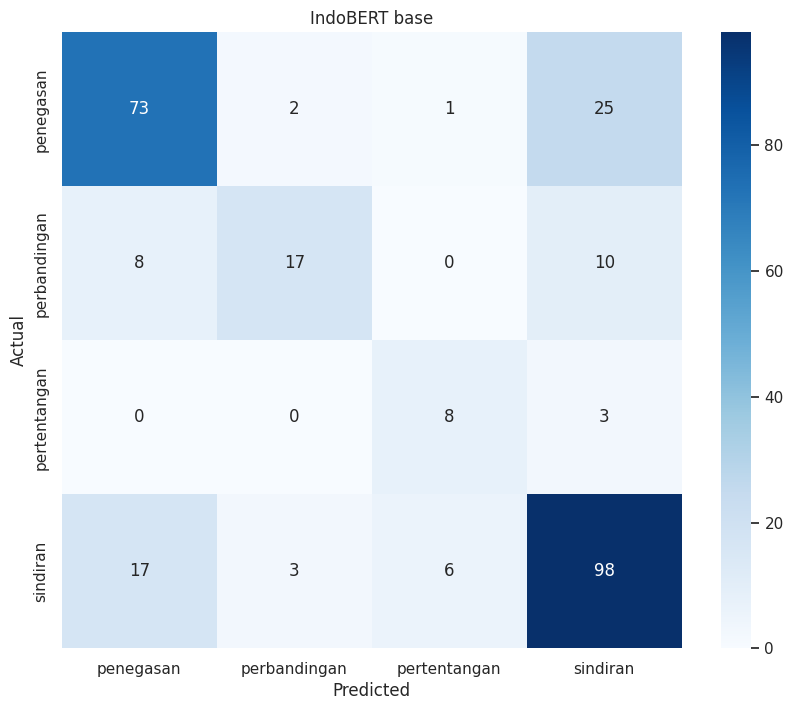

In [ ]:
test_logits = trainer.predict(test_ds).predictions
y_pred = test_logits.argmax(1)
evaluate('IndoBERT base', y_pred)
plot_confusion(y_pred, 'IndoBERT base')

In [ ]:
# training history per epoch
pd.DataFrame(trainer.state.log_history)[['epoch', 'eval_macro_f1', 'eval_accuracy', 'loss']]

,epoch,eval_macro_f1,eval_accuracy,loss
0,1.0,NaN,NaN,1.409462
1,1.0,0.342725,0.608856,NaN
2,2.0,NaN,NaN,1.246217
3,2.0,0.684514,0.763838,NaN
4,3.0,NaN,NaN,1.048715
5,3.0,0.657712,0.734317,NaN
6,4.0,NaN,NaN,0.958921
7,4.0,0.675276,0.741697,NaN
8,5.0,NaN,NaN,0.905719
9,5.0,0.653130,0.726937,NaN


In [ ]:
# search class weights on the val set, then apply them to the test set
val_probs = softmax(trainer.predict(val_ds).predictions, axis=-1)
test_probs = softmax(test_logits, axis=-1)
grid = np.round(np.arange(0.6, 3.01, 0.1), 2)

best_f1, best_w = f1_score(Y_val, val_probs.argmax(1), average='macro'), np.ones(num_labels)
for rest in product(grid, repeat=num_labels - 1):
    w = np.array((1.0,) + rest)
    f1 = f1_score(Y_val, (val_probs * w).argmax(1), average='macro')
    if f1 > best_f1:
        best_f1, best_w = f1, w
print(dict(zip(label_names, best_w.round(2))), 'val:', round(best_f1, 3))
print(classification_report(Y_test, (test_probs * best_w).argmax(1), target_names=label_names, zero_division=0))

{'penegasan': np.float64(1.0), 'perbandingan': np.float64(1.0), 'pertentangan': np.float64(1.0), 'sindiran': np.float64(0.9)} val: 0.707
              precision    recall  f1-score   support

   penegasan       0.74      0.73      0.74       101
perbandingan       0.74      0.49      0.59        35
pertentangan       0.53      0.73      0.62        11
    sindiran       0.72      0.77      0.75       124

    accuracy                           0.72       271
   macro avg       0.68      0.68      0.67       271
weighted avg       0.72      0.72      0.72       271



In [ ]:
# sweep the 'perbandingan' multiplier and see its effect on the test set
j = label_names.index('perbandingan')

def boost(probs, m):
    # multiply the 'perbandingan' probability by m, then pick the top class
    w = np.ones(num_labels); w[j] = m
    return (probs * w).argmax(1)

for m in [1, 2, 3, 5, 8, 12, 20]:
    p = boost(test_probs, m)
    pr, rc, f1, _ = precision_recall_fscore_support(Y_test, p, labels=[j], zero_division=0)
    print(f"{m:>4}x  P={pr[0]:.2f} R={rc[0]:.2f} F1={f1[0]:.2f}  "
          f"macro={f1_score(Y_test, p, average='macro'):.3f}")

   1x  P=0.77 R=0.49 F1=0.60  macro=0.675
   2x  P=0.47 R=0.54 F1=0.51  macro=0.649
   3x  P=0.27 R=0.69 F1=0.39  macro=0.493
   5x  P=0.17 R=0.86 F1=0.28  macro=0.287
   8x  P=0.14 R=0.91 F1=0.24  macro=0.158
  12x  P=0.13 R=1.00 F1=0.23  macro=0.086
  20x  P=0.13 R=1.00 F1=0.23  macro=0.057


In [ ]:
# which original figure of speech (hiperbola / simile / metafora) does the model miss most?
err = pd.DataFrame({
    'raw': training_df2.loc[Y_test.index, 'Majas'].str.strip().str.upper().values,
    'true': [label_names[i] for i in Y_test],
    'pred': [label_names[i] for i in y_pred],
})
sub = err[err.true == 'perbandingan']
print(sub.groupby('raw').agg(n=('raw', 'size'), acc=('pred', lambda s: (s == 'perbandingan').mean())))

            n  acc
raw               
HIPERBOLA  20  0.4
METAFORA   12  0.5
SIMILE      3  1.0


In [ ]:
# pick the multiplier on the val set (not test), then report it on test
cands = [1, 1.5, 2, 2.5, 3, 4, 5, 8]
scores = [f1_score(Y_val, boost(val_probs, m), average='macro') for m in cands]
M = cands[int(np.argmax(scores))]
print('val-optimal multiplier:', M, '| val macro:', round(max(scores), 3))
print(classification_report(Y_test, boost(test_probs, M), target_names=label_names, zero_division=0))

val-optimal multiplier: 1 | val macro: 0.685
              precision    recall  f1-score   support

   penegasan       0.74      0.72      0.73       101
perbandingan       0.77      0.49      0.60        35
pertentangan       0.53      0.73      0.62        11
    sindiran       0.72      0.79      0.75       124

    accuracy                           0.72       271
   macro avg       0.69      0.68      0.67       271
weighted avg       0.73      0.72      0.72       271



In [ ]:
OUT = './majas_classifier_v3_4class'
trainer.save_model(OUT)
tokenizer.save_pretrained(OUT)
joblib.dump(le, f'{OUT}/label_encoder.joblib')
with open(f'{OUT}/metadata.json', 'w') as f:
    json.dump({
        'label_names': label_names, 'id2label': id2label,
        'base_model': MODEL_NAME, 'max_length': 128,
        'n_train': len(X_train), 'n_val': len(X_val), 'n_test': len(X_test),
        'best_checkpoint': trainer.state.best_model_checkpoint,
        'val_macro_f1': trainer.state.best_metric,
        'config': 'lr 1e-5, label_smoothing 0.1, sqrt class weights, early stop patience 4',
        'taxonomy': '4-class, literal promoted out of penegasan (evaluation_2.md §3a)',
    }, f, indent=2)

drive.mount('/content/drive')
shutil.make_archive('/content/drive/MyDrive/majas_classifier_v3_4class', 'zip', OUT)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


'/content/drive/MyDrive/majas_classifier_v3_4class.zip'

# IndoBERT (Tuned)

In [ ]:
def optuna_hp_space(trial):
    return {
        'learning_rate': trial.suggest_float('learning_rate', 1e-5, 5e-5, log=True),
        'per_device_train_batch_size': trial.suggest_categorical('per_device_train_batch_size', [8, 16]),
        'weight_decay': trial.suggest_float('weight_decay', 0.0, 0.1),
        'num_train_epochs': trial.suggest_int('num_train_epochs', 5, 20),
    }

# copy args: Optuna overwrites them on every trial
search_trainer = make_trainer(copy.deepcopy(args))
best_run = search_trainer.hyperparameter_search(
    direction='maximize', backend='optuna', hp_space=optuna_hp_space,
    compute_objective=lambda m: max(m['eval_macro_f1'], search_trainer.state.best_metric or 0),
    n_trials=5)   # lower to 3-5 for a quick first run
print(best_run)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[I 2026-10-19 09:25:24,147] A new study created in memory with name: no-name-be40d8fc-f767-4870-9813-a326b5737a32


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,1.409927,1.313942,0.612546,0.331833,0.556938
2,1.240595,1.093488,0.774908,0.694036,0.770918
3,1.051929,1.013179,0.749077,0.678256,0.761514
4,0.961926,1.032832,0.723247,0.660394,0.725662
5,0.904313,1.045014,0.730627,0.652085,0.741103
6,0.847435,1.068239,0.719557,0.645996,0.724163


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[I 2026-10-19 09:38:47,341] Trial 4 finished with value: 0.637202106107138 and parameters: {'learning_rate': 4.268087791685489e-05, 'per_device_train_batch_size': 16, 'weight_decay': 0.043366817855300825, 'num_train_epochs': 17}. Best is trial 2 with value: 0.6544753917723967.


BestRun(run_id='2', objective=0.6544753917723967, hyperparameters={'learning_rate': 1.3922684303377706e-05, 'per_device_train_batch_size': 16, 'weight_decay': 0.04530577153795309, 'num_train_epochs': 20}, run_summary=None)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,1.400840,1.289212,0.619926,0.338054,0.566098
2,1.210235,1.064260,0.771218,0.687835,0.770508
3,1.036588,1.011206,0.738007,0.661928,0.754237
4,0.952671,1.035877,0.734317,0.669119,0.736203
5,0.892034,1.067382,0.726937,0.660240,0.735985
6,0.824048,1.090008,0.726937,0.654475,0.729332


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

              precision    recall  f1-score   support

   penegasan       0.75      0.75      0.75       101
perbandingan       0.71      0.49      0.58        35
pertentangan       0.70      0.64      0.67        11
    sindiran       0.73      0.79      0.76       124

    accuracy                           0.73       271
   macro avg       0.72      0.67      0.69       271
weighted avg       0.73      0.73      0.73       271

[[76  2  0 23]
 [ 8 17  0 10]
 [ 0  0  7  4]
 [18  5  3 98]]


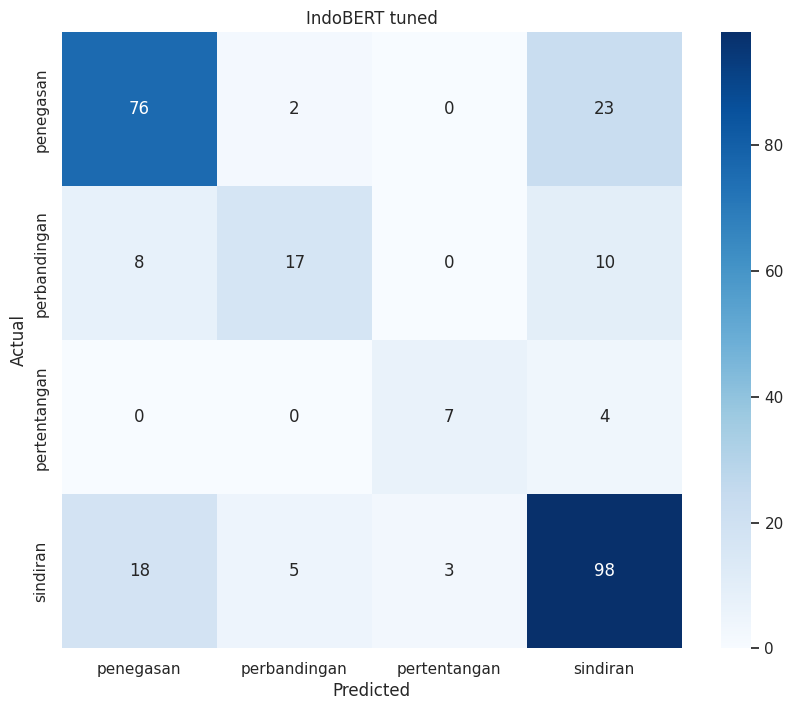

In [ ]:
# retrain from scratch with the best hyperparameters, then evaluate on test
tuned_args = copy.deepcopy(args)
for k, v in best_run.hyperparameters.items():
    setattr(tuned_args, k, v)
tuned_args.output_dir = './results_tuned'

tuned_trainer = make_trainer(tuned_args)
tuned_trainer.train()
y_pred_tuned = tuned_trainer.predict(test_ds).predictions.argmax(-1)
evaluate('IndoBERT tuned', y_pred_tuned)
plot_confusion(y_pred_tuned, 'IndoBERT tuned')

# Model Comparison


In [ ]:
# majority-class baseline: every real model should beat this
majority = np.bincount(Y_test).argmax()
y_major = np.full(len(Y_test), majority)
results['Majority baseline'] = {'accuracy': accuracy_score(Y_test, y_major),
                                'macro_f1': f1_score(Y_test, y_major, average='macro')}

pd.DataFrame(results).T.round(3).sort_values('macro_f1', ascending=False)

,accuracy,macro_f1
IndoBERT tuned,0.731,0.687
NB tuned,0.683,0.676
IndoBERT base,0.723,0.675
SVM tuned,0.694,0.647
NB base,0.679,0.635
SVM base,0.694,0.631
Majority baseline,0.458,0.157


# Predict Data

In [ ]:
def predict_batch(model, texts, tokenizer, batch_size=32):
    model.eval()
    all_probs = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], truncation=True, max_length=128,
                        padding=True, return_tensors='pt').to(model.device)
        with torch.no_grad():
            all_probs.append(torch.softmax(model(**enc).logits, dim=-1).cpu())
    probs = torch.cat(all_probs).numpy()
    return probs.argmax(1), probs.max(1), probs   # predicted id, confidence, all class probs

output_df, start_date, end_date = prepare_time(
    predict_df[['Date', 'Media', 'Type', 'Mentions', 'Sentiment', 'Author']])
output_df['prepro_text'] = output_df['Mentions'].fillna('').apply(clean)
mask = output_df['prepro_text'].str.strip().ne('')   # skip empty texts
print(f'predicting {mask.sum()} rows, skipping {(~mask).sum()} empty')

predicting 6191 rows, skipping 18 empty


In [ ]:
# base model; swap to tuned_trainer.model if the tuned one scored better
pred_ids, confidences, probs = predict_batch(model, output_df.loc[mask, 'prepro_text'].tolist(), tokenizer)

output_df.loc[mask, 'predicted_majas'] = [label_names[p] for p in pred_ids]
output_df.loc[mask, 'confidence'] = confidences
for j, cls in enumerate(label_names):
    output_df.loc[mask, f'prob_{cls}'] = probs[:, j]
output_df.head(20)

,Date,Media,Type,Mentions,Sentiment,Author,prepro_text,predicted_majas,confidence,prob_penegasan,prob_perbandingan,prob_pertentangan,prob_sindiran
6208,2026-10-16 00:00:00,Twitter,rt,"RT Pelantikan 2 Pejabat TNI, Prabowo Tunjuk Maruli Simanjuntak Jadi Wakil Panglima dan Tandyo Budi Revita sebagai KSAD #TNI #Prabowo #MaruliSimanjuntak #TandyoBudi #KSAD #Kabarterdepan https://t.co/kAIJbNasF1 https://t.co/7EL5sO67mu",Negative,@kabarterdepanmr,"RT Pelantikan 2 Pejabat TNI, Prabowo Tunjuk Maruli Simanjuntak Jadi Wakil Panglima dan Tandyo Budi Revita sebagai KSAD TNI Prabowo MaruliSimanjuntak TandyoBudi KSAD Kabarterdepan",sindiran,0.524966,0.158831,0.192090,0.124113,0.524966
6207,2026-10-16 00:00:03,Youtube,mention,???? INDONESIA MAJU #prabowo #viralvideo #youtubeshorts #viral #video #fyp #viralshorts #shorts,Positive,calonpemimpin,???? INDONESIA MAJU prabowo viralvideo youtubeshorts viral video fyp viralshorts shorts,sindiran,0.443976,0.116499,0.252507,0.187018,0.443976
6206,2026-10-16 00:00:06,Youtube,mention,"&quot;KALAU PAK PRABOWO SAMPAI AKHIR 2026 TIDAK MELAKUKAN APA-APA ATAS KELUARGA SOLO, BELIAU KALAH&quot;. For Partnership, Please Contact:\nbisnis@forumkeadilan.com\nhttps://wa.me/628119899090\n\nDapatkan informasi terkini isu-isu hukum dan politik di Indonesia dengan Forum Keadilan. Download aplikasinya sekarang!\nPlaystore https://tinyurl.com/forumkeadilanplaystore\nAppStore https://tinyurl.com/forumkeadilanapps\nPortal https://forumkeadilan.com/\n\nApakah Anda peduli dengan isu-isu keadilan sosial dan ingin berkontribusi dalam menciptakan perubahan positif? Forum Keadilan adalah tempat yang tepat untuk Anda! Ikuti kami sekarang di:\nYouTube https://www.youtube.com/@forumkeadilanTV\nInstagram https://www.instagram.com/forumkeadilantv\nFB https://www.facebook.com/forumkeadilandotcom\nTiktok https://www.tiktok.com/@forumkeadilantv\n\n#menukwulandari #prabowosubianto #gibranrakabumingraka #jokowi #irianajokowi #keluargasolo #kertenegara #aliansirakyatmenggugat #arm #wakilpresiden #pencalonanwapres #politikindonesia #politiknasional #madilog #podcastmadilog #margisyarif #presidensial #pemerintahanprabowo #beritanasional #forumkeadilan",Positive,Forum Keadilan TV,"""KALAU PAK PRABOWO SAMPAI AKHIR 2026 TIDAK MELAKUKAN APA-APA ATAS KELUARGA SOLO, BELIAU KALAH"". For Partnership, Please Contact: bisnis .com Dapatkan informasi terkini isu-isu hukum dan politik di Indonesia dengan Forum Keadilan. Download aplikasinya sekarang! Playstore AppStore Portal Apakah Anda peduli dengan isu-isu keadilan sosial dan ingin berkontribusi dalam menciptakan perubahan positif? Forum Keadilan adalah tempat yang tepat untuk Anda! Ikuti kami sekarang di: YouTube Instagram FB Tiktok menukwulandari prabowosubianto gibranrakabumingraka jokowi irianajokowi keluargasolo kertenegara aliansirakyatmenggugat arm wakilpresiden pencalonanwapres politikindonesia politiknasional madilog podcastmadilog margisyarif presidensial pemerintahanprabowo beritanasional forumkeadilan",sindiran,0.538297,0.150569,0.175942,0.135192,0.538297
6205,2026-10-16 00:00:07,Youtube,mention,PRESIDEN PRABOWO INSTRUKSIKAN TRANSFORMASI MENYELURUH PLN. Saksikan update informasi terbaru di SurabayaTV channel digital 35 frekuensi 586.\n\nSurabayaTV\nTV Kota Pahlawan\n\n\nIKUTI KAMI DI SOSIAL MEDIA:\nFacebook: https://www.facebook.com/SurabayaTv/\nTiktok: https://www.tiktok.com/@surabayatv\nInstagram: https://www.instagram.com/surabayatv.official\nYoutube: https://www.youtube.com/channel/surabayatv\n\nKami sangat berterima kasih atas perhatian dan kontribusi penonton dalam membagikan dan menyukai channel kami...\n\nSalam SurabayaTV...\n\n#SURABAYATV #FRESH #UPDATE,Positive,NEWS SURABAYA TV,PRESIDEN PRABOWO INSTRUKSIKAN TRANSFORMASI MENYELURUH PLN. Saksikan update informasi terbaru di SurabayaTV channel digital 35 frekuensi 586. SurabayaTV TV Kota Pahlawan IKUTI KAMI DI SOSIAL MEDIA: Facebook: Tiktok: Instagram: Youtube: Kami sangat berterima beri atas perhatian dan kontribusi penonton dalam m

In [ ]:
print(output_df['predicted_majas'].value_counts(dropna=False, normalize=True))
print(output_df['confidence'].describe())

# read the 10 least-confident predictions yourself: the fastest way
# to catch a preprocessing mismatch between train and predict
output_df.nsmallest(10, 'confidence')[['Mentions', 'predicted_majas', 'confidence']]

predicted_majas
sindiran        0.882429
penegasan       0.082139
perbandingan    0.032050
nan             0.002899
pertentangan    0.000483
Name: proportion, dtype: float64
count    6191.000000
mean        0.470074
std         0.076971
min         0.265968
25%         0.406975
50%         0.467177
75%         0.522403
max         0.697304
Name: confidence, dtype: float64


,Mentions,predicted_majas,confidence
3735,RIP,penegasan,0.265968
794,RT @prabowo @RajaJuliAntoni https://t.co/bgTlHVvXMf,sindiran,0.270780
2443,Yang udah muak bgt sama pemerintahan Prabowo angkat tangan,sindiran,0.270893
3742,prabowo,penegasan,0.275639
3423,prabowo,penegasan,0.275639
2635,prabowo,penegasan,0.275639
2023,prabowo ajg,perbandingan,0.275946
2721,Prabowo di ganti sama Joko Widodo,perbandingan,0.277639
3809,Betulll,perbandingan,0.279569
4947,The student and college student demonstrations are no longer pure @EmmanuelMacron @prabowo @GiorgiaMeloni @EP_President @andyburnham @LawrenceWongST @AlboMP @Claudiashein https://t.co/fTaTTfVAXn,penegasan,0.279999


In [ ]:
output_df.to_csv('predicted_results.csv', index=False, encoding='utf-8-sig')
files.download('predicted_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#### (Hide)

In [ ]:
#!df -h /
#!du -sh ./results_narrative_classifier

In [ ]:
#model.save_pretrained("./best_model_epoch11")
#tokenizer.save_pretrained("./best_model_epoch11")
#!ls -la ./best_model_epoch11

In [ ]:
#!rm -rf ./results_narrative_classifier
# !df -h /

In [ ]:
# eval_trainer = WeightedTrainer(
#     model=model,                    # your epoch-11 weights, still in memory
#     args=args,
#     eval_dataset=test_ds,
#     data_collator=collator,
#     compute_metrics=compute_metrics,
# )
#  print(eval_trainer.evaluate(test_ds))


In [ ]:
# import numpy as np
# from sklearn.metrics import classification_report, f1_score, accuracy_score

# y_true = np.array([test_ds[i]["labels"] for i in range(len(test_ds))])
# majority = np.bincount(y_true).argmax()
# y_major = np.full_like(y_true, majority)

# print("majority acc:     ", accuracy_score(y_true, y_major))
# print("majority macro F1:", f1_score(y_true, y_major, average="macro"))

In [ ]:
# preds  = eval_trainer.predict(test_ds)
# y_pred = preds.predictions.argmax(-1)
# print(classification_report(y_true, y_pred, target_names=label_names, zero_division=0))
# print(confusion_matrix(y_true, y_pred))

#### End Hide

In [ ]:
# def predict_batch(model, texts, tokenizer, batch_size=32):
#     model.eval()
#     all_preds, all_confidences = [], []
#     for i in range(0, len(texts), batch_size):
#         batch = texts[i:i+batch_size]
#         enc = tokenizer(batch, truncation=True, max_length=128, padding=True, return_tensors="pt")
#         with torch.no_grad():
#             logits = model(**enc).logits
#             probs = torch.softmax(logits, dim=-1)
#             conf, pred = torch.max(probs, dim=-1)
#         all_preds.extend(pred.tolist())
#         all_confidences.extend(conf.tolist())
#     return all_preds, all_confidences

In [ ]:
# output_df = predict_df[['Date','Media','Type','Mentions','Sentiment','Author']].copy()
# output_df, start_date, end_date = prepare_time(output_df)
# output_df['prepro_text'] = output_df['Mentions'].apply(clean)
# mask = output_df['prepro_text'].str.strip().ne("")
# print(f"predicting {mask.sum()} rows, skipping {(~mask).sum()} empty")

In [ ]:
# pred_ids, confidences, probs = predict_batch(
#     model, output_df.loc[mask, 'prepro_text'].tolist(), tokenizer
# )

In [ ]:
# output_df.loc[mask, 'predicted_majas'] = [label_names[p] for p in pred_ids]
# output_df.loc[mask, 'confidence'] = confidences
# for j, cls in enumerate(label_names):
#     output_df.loc[mask, f'prob_{cls}'] = [p[j] for p in probs]

# output_df.head(20)

In [ ]:
# print(output_df['predicted_majas'].value_counts(dropna=False, normalize=True))
# print(output_df['confidence'].describe())

# # read the 10 least-confident predictions yourself — this is the fastest way
# # to catch a preprocessing mismatch between train and predict
# pd.set_option('display.max_colwidth', None)
# output_df.nsmallest(10, 'confidence')[['Mentions','predicted_majas','confidence']]


In [ ]:
# output_df.to_csv('predicted_results.csv', index=False, encoding='utf-8-sig')
# from google.colab import files
# files.download('predicted_results.csv')
